# testlauf: welches kursmodell wäre am besten gewesen?
**Team 5 (Roland, Leo, Tobias)** · Zusatz zu **07_modelle.ipynb**

Ziel: In **07_modelle.ipynb** haben wir drei Modelle verglichen, hier prüfen wir alle Klassifikations-Modelle aus week05–07 und ein paar weitere. Alle laufen unter denselben Bedingungen (gleiche Features, gleiche 5 Folds, gleiche Metrik), so sehen wir, ob wir mit einem anderen Modell besser gewesen wären. Wie in 07 nutzen wir nur Train-Teil und Cross-Validation, den Test-Teil fassen wir nicht an.

Ergebnis vorab: Der Random Forest aus **07_modelle.ipynb** war die richtige Wahl (ROC-AUC 0,847). Stacking und Gradient Boosting liegen mit 0,848 gleichauf, der Unterschied ist kleiner als die Schwankung zwischen den Folds. Naive Bayes ist mit 0,711 klar am schlechtesten.

Vorher laufen lassen: **06_features.ipynb** (für **data/fd_features.csv**) und **07_modelle.ipynb** (für **models/fd_best_model.joblib**). Eingabe sind **data/fd_features.csv**, **data/fd_split.csv** und **models/fd_best_model.joblib**, bewertet wird mit **fd_utils.py**, Ausgabedateien gibt es keine.

## teil a: setup und daten laden

In [1]:
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import AdaBoostClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import StackingClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from fd_utils import RANDOM_STATE, evaluate_cv

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

DATA_DIR = Path("data")
MODEL_DIR = Path("models")

In [2]:
df = pd.read_csv(DATA_DIR / "fd_features.csv")
df_split = pd.read_csv(DATA_DIR / "fd_split.csv")

# split an die kunden hängen
df = df.merge(df_split, on="client_id", how="left")

# nur der train-teil
df_train = df[df["split"] == "train"]

# das sind keine features
nicht_features = ["client_id", "creation_date", "split", "target"]

X_train = df_train.drop(columns=nicht_features)
y_train = df_train["target"]

print("X_train:", X_train.shape)
print("Betrugsquote:", round(y_train.mean(), 4))

X_train: (108394, 30)
Betrugsquote: 0.0558


Der Train-Teil hat 108.394 Kunden und 30 Features, die Betrugsquote liegt bei 5,58 %.

## teil b: die modelle aus 07 noch einmal
Damit alles in einer Tabelle steht, rechnen wir die drei Modelle aus 07 hier noch mal mit. Den getunten Random Forest laden wir direkt aus **models/fd_best_model.joblib**.

Die Vorbereitung (One-Hot, **log**, Skalieren) ist dieselbe wie in 07. KNN, SVC, Naive Bayes und das neuronale Netz brauchen sie später auch.

In [3]:
kategorien = ["disrict", "client_catg", "region"]

# schief verteilte spalten: erst log(1 + x), dann skalieren
schief = ["cons_median_elec", "cons_mean_elec", "cons_std_elec",
          "cons_median_gaz", "cons_mean_gaz", "cons_std_gaz",
          "month_median_elec", "month_std_elec", "month_median_gaz", "month_std_gaz",
          "max_drop", "max_rise", "mean_abs_change", "trend_ratio", "cv_elec", "cv_gaz"]

# alle anderen spalten sind normale zahlen
zahlen = []
for spalte in X_train.columns:
    if spalte not in kategorien and spalte not in schief:
        zahlen.append(spalte)

log_und_skalieren = Pipeline([
    ("log", FunctionTransformer(np.log1p)),
    ("scaler", StandardScaler()),
])

vorbereitung = ColumnTransformer([
    ("kategorien", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), kategorien),
    ("schief", log_und_skalieren, schief),
    ("zahlen", StandardScaler(), zahlen),
])

In [4]:
# die drei modelle aus 07
logreg = Pipeline([
    ("vorbereitung", vorbereitung),
    ("logreg", LogisticRegression(class_weight="balanced", max_iter=2000)),
])

rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=20, class_weight="balanced",
                            n_jobs=-1, random_state=RANDOM_STATE)

ada = AdaBoostClassifier(n_estimators=200, random_state=RANDOM_STATE)

# der getunte random forest aus 07
rf_tuned = joblib.load(MODEL_DIR / "fd_best_model.joblib")

ergebnis_logreg = evaluate_cv(logreg, X_train, y_train, "Logistische Regression")
ergebnis_rf = evaluate_cv(rf, X_train, y_train, "Random Forest")
ergebnis_ada = evaluate_cv(ada, X_train, y_train, "AdaBoost")
ergebnis_rf_tuned = evaluate_cv(rf_tuned, X_train, y_train, "Random Forest (getunt, aus 07)")

ergebnisse = pd.concat([ergebnis_logreg, ergebnis_rf, ergebnis_ada, ergebnis_rf_tuned])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202


Der getunte Random Forest liegt mit 0,847 vorn, der ungetunte knapp dahinter (0,844). Logistische Regression (0,813) und AdaBoost (0,816) sind deutlich schwächer.

## teil c: entscheidungsbaum
Ein einzelner Baum (week07). Ohne Grenzen lernt er die Train-Daten auswendig, deshalb begrenzen wir Tiefe und Blattgröße.

In [5]:
baum = DecisionTreeClassifier(max_depth=10, min_samples_leaf=50, class_weight="balanced",
                              random_state=RANDOM_STATE)

ergebnis_baum = evaluate_cv(baum, X_train, y_train, "Entscheidungsbaum")

ergebnisse = pd.concat([ergebnisse, ergebnis_baum])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142


Der einzelne Baum kommt auf 0,803 und ist damit schwächer als der Random Forest (0,847).

## teil d: knn
KNN (week06) vergleicht jeden Kunden mit seinen ähnlichsten Nachbarn. Weil KNN mit Abständen rechnet, braucht es die skalierte Vorbereitung. Mit **n_neighbors=50** ergibt sich eine feinere Wahrscheinlichkeit als mit wenigen Nachbarn, und das ist wichtig für die ROC-AUC. Der Schritt dauert ein paar Minuten.

In [6]:
knn = Pipeline([
    ("vorbereitung", vorbereitung),
    ("knn", KNeighborsClassifier(n_neighbors=50)),
])

ergebnis_knn = evaluate_cv(knn, X_train, y_train, "KNN (k=50)")

ergebnisse = pd.concat([ergebnisse, ergebnis_knn])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572


KNN kommt auf 0,815, etwa so viel wie die logistische Regression. Der Recall ist fast 0 (0,009): Bei der Schwelle 0,5 sagt KNN fast nie „Betrug“.

## teil e: voting und stacking
Beide Methoden (week07, Ensemble-Methoden) kombinieren mehrere Modelle. Voting nimmt den Mittelwert der Wahrscheinlichkeiten von logistischer Regression, Random Forest und AdaBoost. Beim Stacking lernt eine logistische Regression, wie stark sie jedes der drei Modelle gewichten soll.

Stacking trainiert jedes Modell mehrmals und dauert deshalb am längsten.

In [7]:
# diese drei modelle werden kombiniert
modelle = [("logreg", logreg), ("rf", rf_tuned), ("ada", ada)]

voting = VotingClassifier(modelle, voting="soft")

ergebnis_voting = evaluate_cv(voting, X_train, y_train, "Voting (LogReg + RF + Ada)")

ergebnisse = pd.concat([ergebnisse, ergebnis_voting])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196


In [8]:
stacking = StackingClassifier(modelle, final_estimator=LogisticRegression(max_iter=2000), cv=3)

ergebnis_stacking = evaluate_cv(stacking, X_train, y_train, "Stacking (LogReg + RF + Ada)")

ergebnisse = pd.concat([ergebnisse, ergebnis_stacking])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798


Voting (0,841) ist etwas schlechter als der getunte Random Forest allein (0,847). Stacking (0,848) ist nur um 0,001 besser, das ist kein echter Unterschied.

## teil f: svc (nur auf einer stichprobe)
Die Support Vector Machine (week07) wird bei vielen Zeilen sehr langsam, bei über 100.000 Kunden würde sie Stunden brauchen. Wir testen sie deshalb nur auf 10.000 zufälligen Kunden. Damit der Vergleich fair ist, rechnen wir den getunten Random Forest auf genau derselben Stichprobe noch mal.

In [9]:
# 10.000 zufällige kunden aus dem train-teil
stichprobe = df_train.sample(n=10000, random_state=RANDOM_STATE)

X_klein = stichprobe.drop(columns=nicht_features)
y_klein = stichprobe["target"]

svc = Pipeline([
    ("vorbereitung", vorbereitung),
    ("svc", SVC(class_weight="balanced", random_state=RANDOM_STATE)),
])

ergebnis_svc = evaluate_cv(svc, X_klein, y_klein, "SVC (10.000 Kunden)")
ergebnis_rf_klein = evaluate_cv(rf_tuned, X_klein, y_klein, "Random Forest getunt (10.000 Kunden)")

stichprobe_ergebnisse = pd.concat([ergebnis_svc, ergebnis_rf_klein])
stichprobe_ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
SVC (10.000 Kunden),0.803,0.020,0.661,0.168
Random Forest getunt (10.000 Kunden),0.811,0.011,0.625,0.178


Auf derselben Stichprobe liegt die SVC (0,803) knapp hinter dem Random Forest (0,811). Die Werte sind niedriger als auf allen Kunden, weil die Modelle weniger Daten zum Lernen haben, wichtig ist nur der Vergleich der beiden Zeilen.

## teil g: gradient boosting (statt xgboost)
XGBoost kam in week07 vor, läuft auf unseren Macs aber nicht, weil eine Systembibliothek (**libomp**) fehlt. scikit-learn hat mit **HistGradientBoostingClassifier** eine Variante nach derselben Idee eingebaut: Viele kleine Bäume werden nacheinander gebaut, und jeder korrigiert die Fehler der vorherigen.

Das ist dasselbe Prinzip wie bei AdaBoost, nur lernt jeder neue Baum direkt aus den Fehlern statt über Gewichte.

In [10]:
hgb = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, class_weight="balanced",
                                     random_state=RANDOM_STATE)

ergebnis_hgb = evaluate_cv(hgb, X_train, y_train, "Gradient Boosting (HistGB)")

ergebnisse = pd.concat([ergebnisse, ergebnis_hgb])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167


Gradient Boosting kommt auf 0,848 und liegt damit gleichauf mit Stacking und dem getunten Random Forest.

## teil h: weitere gängige methoden (nicht im kurs)
Diese Modelle kamen im Kurs nicht dran, gehören aber zum Standard-Werkzeug für Klassifikation, wir testen sie nur zum Vergleich:

| Modell | Idee |
|---|---|
| Naive Bayes | rechnet für jede Spalte einzeln aus, wie typisch der Wert für Betrug ist, und multipliziert alles |
| Bagging | viele Entscheidungsbäume auf zufälligen Stichproben, dann Mittelwert (wie Random Forest, aber jeder Baum sieht alle Spalten) |
| Extra Trees | wie Random Forest, aber die Grenzen in den Bäumen werden zufällig gewählt |
| Neuronales Netz (MLP) | mehrere Schichten aus kleinen Rechen-Einheiten, braucht skalierte Daten |

In [11]:
naive_bayes = Pipeline([
    ("vorbereitung", vorbereitung),
    ("nb", GaussianNB()),
])

ergebnis_nb = evaluate_cv(naive_bayes, X_train, y_train, "Naive Bayes")

ergebnisse = pd.concat([ergebnisse, ergebnis_nb])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167
Naive Bayes,0.711,0.006,0.846,0.081


In [12]:
# der baum, der im bagging viele male trainiert wird
bagging_baum = DecisionTreeClassifier(min_samples_leaf=20, class_weight="balanced")

bagging = BaggingClassifier(bagging_baum, n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE)

ergebnis_bagging = evaluate_cv(bagging, X_train, y_train, "Bagging (Bäume)")

ergebnisse = pd.concat([ergebnisse, ergebnis_bagging])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167
Naive Bayes,0.711,0.006,0.846,0.081


In [13]:
extra_trees = ExtraTreesClassifier(n_estimators=300, min_samples_leaf=20, max_features=0.3,
                                   class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE)

ergebnis_extra_trees = evaluate_cv(extra_trees, X_train, y_train, "Extra Trees")

ergebnisse = pd.concat([ergebnisse, ergebnis_extra_trees])
ergebnisse

/Users/bootcamp/workspace/weeks/week08/ds-ml-fraud-detection/.venv/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167
Naive Bayes,0.711,0.006,0.846,0.081


In [14]:
mlp = Pipeline([
    ("vorbereitung", vorbereitung),
    ("mlp", MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=200,
                          random_state=RANDOM_STATE)),
])

ergebnis_mlp = evaluate_cv(mlp, X_train, y_train, "Neuronales Netz (MLP)")

ergebnisse = pd.concat([ergebnisse, ergebnis_mlp])
ergebnisse

,ROC-AUC,ROC-AUC std,Recall,Precision
Logistische Regression,0.813,0.006,0.750,0.146
Random Forest,0.844,0.004,0.667,0.197
AdaBoost,0.816,0.005,0.010,0.343
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Entscheidungsbaum,0.803,0.009,0.734,0.142
KNN (k=50),0.815,0.005,0.009,0.572
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167
Naive Bayes,0.711,0.006,0.846,0.081


Extra Trees (0,845), Bagging (0,841) und das neuronale Netz (0,839) liegen nah am Random Forest, aber nicht darüber. Naive Bayes fällt mit 0,711 deutlich ab.

## teil i: gesamtvergleich
### welches modell hat die beste roc-auc?

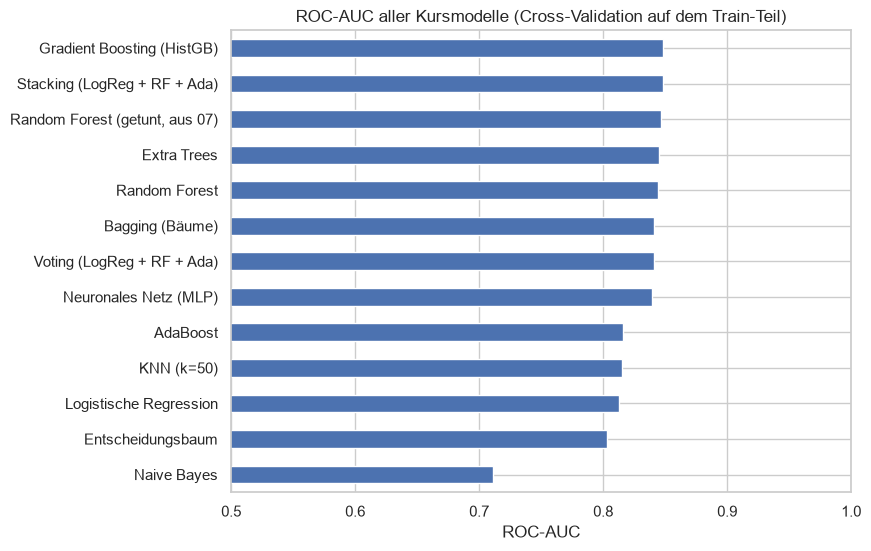

,ROC-AUC,ROC-AUC std,Recall,Precision
Stacking (LogReg + RF + Ada),0.848,0.005,0.011,0.798
Gradient Boosting (HistGB),0.848,0.004,0.754,0.167
"Random Forest (getunt, aus 07)",0.847,0.005,0.664,0.202
Extra Trees,0.845,0.004,0.717,0.181
Random Forest,0.844,0.004,0.667,0.197
Voting (LogReg + RF + Ada),0.841,0.006,0.662,0.196
Bagging (Bäume),0.841,0.005,0.484,0.271
Neuronales Netz (MLP),0.839,0.007,0.072,0.574
AdaBoost,0.816,0.005,0.010,0.343
KNN (k=50),0.815,0.005,0.009,0.572


In [15]:
# balken nach ROC-AUC sortiert
roc_auc_sortiert = ergebnisse["ROC-AUC"].sort_values()

roc_auc_sortiert.plot(kind="barh", figsize=(8, 6))
plt.title("ROC-AUC aller Kursmodelle (Cross-Validation auf dem Train-Teil)")
plt.xlabel("ROC-AUC")
plt.xlim(0.5, 1)
plt.show()

ergebnisse.sort_values("ROC-AUC", ascending=False)

**was sehen wir?**

| Platz | Modell | im Kurs? | ROC-AUC |
|---|---|---|---|
| 1 | Stacking (LogReg + RF + Ada) | ja | 0,848 |
| 2 | Gradient Boosting (HistGB, statt XGBoost) | ja (als XGBoost) | 0,848 |
| 3 | Random Forest (getunt, aus 07) | ja | 0,847 |
| 4 | Extra Trees | nein | 0,845 |
| 5 | Random Forest (ungetunt) | ja | 0,844 |
| 6 | Voting (LogReg + RF + Ada) | ja | 0,841 |
| 7 | Bagging (Bäume) | nein | 0,841 |
| 8 | Neuronales Netz (MLP) | nein | 0,839 |
| 9 | AdaBoost | ja | 0,816 |
| 10 | KNN (k=50) | ja | 0,815 |
| 11 | Logistische Regression | ja | 0,813 |
| 12 | Entscheidungsbaum | ja | 0,803 |
| 13 | Naive Bayes | nein | 0,711 |
| – | SVC (nur 10.000 Kunden) | ja | 0,803 (RF auf derselben Stichprobe: 0,811) |

## zusammenfassung
Der Random Forest aus **07_modelle.ipynb** war die richtige Wahl, kein anderes Modell ist spürbar besser.

Die ersten drei liegen gleichauf: 0,001 Unterschied ist viel kleiner als die Schwankung zwischen den Folds (std 0,004–0,005), und der Random Forest ist davon das einfachste Modell. Viele Bäume gewinnen, auf den Plätzen 1–7 stecken überall viele Entscheidungsbäume, der einzelne Baum liegt nur auf Platz 12. Naive Bayes ist klar am schlechtesten, weil er jede Spalte einzeln betrachtet, aber gerade die Kombinationen von Spalten verraten Betrug.

Der Recall ist bei Stacking, AdaBoost, KNN und MLP fast 0: Diese Modelle gleichen die wenigen Betrugsfälle nicht aus und sagen bei der Schwelle 0,5 fast nie „Betrug“. Für die ROC-AUC und die Top-10-%-Auswahl ist das egal, weil dort nur die Reihenfolge der Kunden zählt.

## nächster schritt
Wir bleiben beim Random Forest aus **07_modelle.ipynb**, an den anderen Notebooks ändert sich nichts. Für die Präsentation: „Wir haben alle Klassifikations-Modelle aus dem Kurs und ein paar weitere getestet. Der Random Forest ist gleichauf mit den besten, aber einfacher und schneller.“